In [1]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import time
import seaborn as sns
import plotly.express as px
pd.set_option('display.max_rows', None)  # Show all rows
pd.set_option('display.max_columns', None) # Show all columns
pd.set_option('display.width', 1000) # Adjust display width

In [2]:
df = pd.read_csv('WiFI_and_MQTT/balanced_dataset.csv')

In [3]:
df.head()

,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,cwr_flag_number,ack_count,syn_count,fin_count,rst_count,HTTP,HTTPS,DNS,Telnet,SMTP,SSH,IRC,TCP,UDP,DHCP,ARP,ICMP,IGMP,IPv,LLC,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,Attack_Type,Label,Attack
0,695746.0,6.0,64.0,184.999355,184.999355,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,577.5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,8217.0,1494.0,1494.0,1494.000000,0.000000,1494.0,1.667905e-03,5.5,54.662601,0.000000,0.000000,0.0,38.5,Spoofing,1,ARP Spoofing
1,3637961.1,17.0,64.0,173.228536,173.228536,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,2447.1,218.7,1144.0,534.579762,396.741844,347.9,6.082892e-03,5.5,32.138960,561.077696,175443.801999,0.9,38.5,Spoofing,1,ARP Spoofing
2,1702906.8,17.0,64.0,180.256940,180.256940,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1693.8,87.0,1034.8,302.935238,337.026851,262.4,6.571817e-03,5.5,24.147095,476.627944,140421.963059,0.9,38.5,Spoofing,1,ARP Spoofing
3,5339.5,6.0,119.0,0.088987,0.088987,0.0,0.0,0.0,0.0,0.5,1.0,0.0,0.0,0.0,0.0,0.0,70.1,0.0,0.5,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,476.5,55.2,111.6,83.336190,24.655715,84.3,9.981289e-02,5.5,12.879015,34.868446,729.505696,0.9,38.5,Spoofing,1,ARP Spoofing
4,2484636.8,17.0,64.0,180.866422,180.866422,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,4405.8,102.6,686.0,284.489893,223.962943,304.0,1.694024e+08,13.5,23.888075,317.003649,50281.331821,1.0,244.6,Spoofing,1,ARP Spoofing


In [4]:
df.duplicated().sum()

0

In [5]:
df.isnull().any().any()

False

In [6]:
df.isnull().sum()

Header_Length      0
Protocol Type      0
Duration           0
Rate               0
Srate              0
Drate              0
fin_flag_number    0
syn_flag_number    0
rst_flag_number    0
psh_flag_number    0
ack_flag_number    0
ece_flag_number    0
cwr_flag_number    0
ack_count          0
syn_count          0
fin_count          0
rst_count          0
HTTP               0
HTTPS              0
DNS                0
Telnet             0
SMTP               0
SSH                0
IRC                0
TCP                0
UDP                0
DHCP               0
ARP                0
ICMP               0
IGMP               0
IPv                0
LLC                0
Tot sum            0
Min                0
Max                0
AVG                0
Std                0
Tot size           0
IAT                0
Number             0
Magnitue           0
Radius             0
Covariance         0
Variance           0
Weight             0
Attack_Type        0
Label              0
Attack       

In [7]:
df.shape

(699409, 48)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699409 entries, 0 to 699408
Data columns (total 48 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Header_Length    699409 non-null  float64
 1   Protocol Type    699409 non-null  float64
 2   Duration         699409 non-null  float64
 3   Rate             699409 non-null  float64
 4   Srate            699409 non-null  float64
 5   Drate            699409 non-null  float64
 6   fin_flag_number  699409 non-null  float64
 7   syn_flag_number  699409 non-null  float64
 8   rst_flag_number  699409 non-null  float64
 9   psh_flag_number  699409 non-null  float64
 10  ack_flag_number  699409 non-null  float64
 11  ece_flag_number  699409 non-null  float64
 12  cwr_flag_number  699409 non-null  float64
 13  ack_count        699409 non-null  float64
 14  syn_count        699409 non-null  float64
 15  fin_count        699409 non-null  float64
 16  rst_count        699409 non-null  floa

In [9]:
df = df.drop(['Attack', 'Label', 'Drate'], axis=1)

In [10]:
df.isnull().sum()

Header_Length      0
Protocol Type      0
Duration           0
Rate               0
Srate              0
fin_flag_number    0
syn_flag_number    0
rst_flag_number    0
psh_flag_number    0
ack_flag_number    0
ece_flag_number    0
cwr_flag_number    0
ack_count          0
syn_count          0
fin_count          0
rst_count          0
HTTP               0
HTTPS              0
DNS                0
Telnet             0
SMTP               0
SSH                0
IRC                0
TCP                0
UDP                0
DHCP               0
ARP                0
ICMP               0
IGMP               0
IPv                0
LLC                0
Tot sum            0
Min                0
Max                0
AVG                0
Std                0
Tot size           0
IAT                0
Number             0
Magnitue           0
Radius             0
Covariance         0
Variance           0
Weight             0
Attack_Type        0
dtype: int64

In [12]:
df['Attack_Type'].unique()

array(['Spoofing', 'DDoS', 'DoS', 'MQTT', 'Benign', 'Recon'], dtype=object)

<h2>Outliers</h2>

In [13]:
df2 = df.copy()

In [14]:
df2 = df2.drop(['IGMP', 'IRC', 'SSH', 'SMTP', 'DHCP', 'Telnet', 'cwr_flag_number'], axis=1)

In [16]:
df2['Attack_Type'].unique()

array(['Spoofing', 'DDoS', 'DoS', 'MQTT', 'Benign', 'Recon'], dtype=object)

In [17]:
attack_mapping = {
    'Benign': 0,
    'Spoofing': 1,
    'DDoS': 2,
    'DoS': 3,
    'MQTT': 4,
    'Recon': 5
}

df2['Attack_Type'] = df2['Attack_Type'].apply(lambda x: attack_mapping[x])

In [18]:
df2['Attack_Type'].unique()

array([1, 2, 3, 4, 0, 5], dtype=int64)

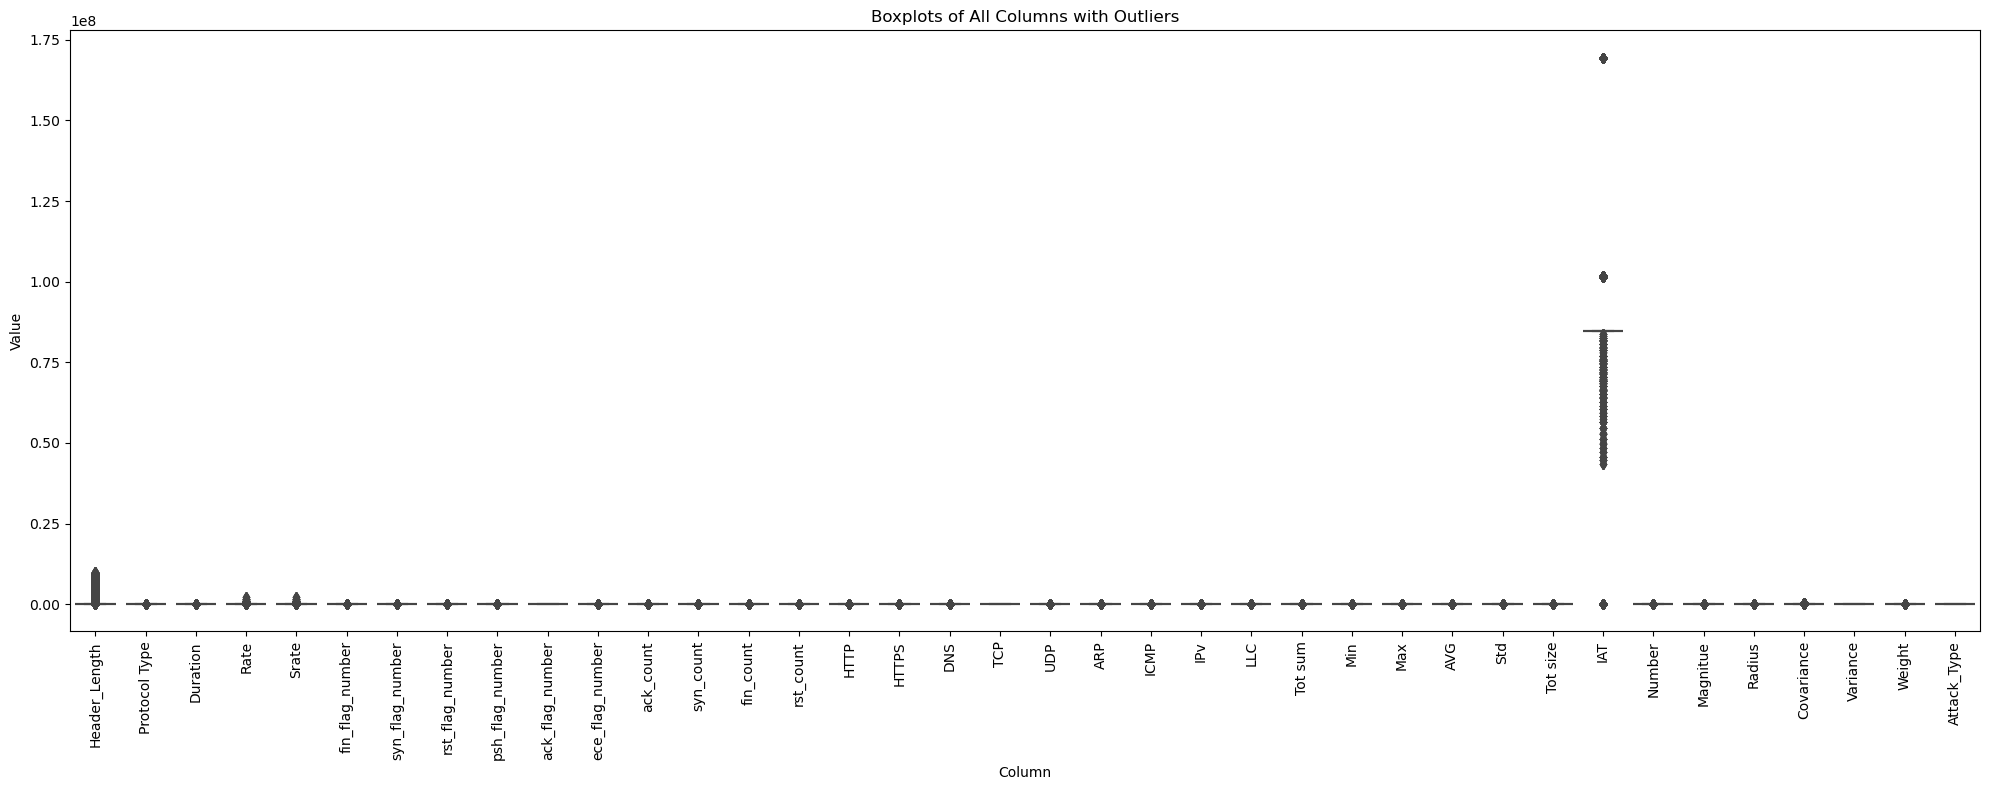

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert wide df (55 columns) into long format
df_melted = df2.melt(var_name="Column", value_name="Value")

plt.figure(figsize=(20, 8))  # wider figure to fit all columns on x-axis
sns.boxplot(x="Column", y="Value", data=df_melted)

plt.xticks(rotation=90)  # rotate labels for readability
plt.title("Boxplots of All Columns with Outliers")
plt.tight_layout()
plt.show()

In [20]:
outliers_per_column = {}
for col in df2.select_dtypes(include=np.number).columns:
    Q1 = df2[col].quantile(0.25)
    Q3 = df2[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df2[(df2[col] < lower) | (df2[col] > upper)]
    outliers_per_column[col] = len(outliers)

In [21]:
outliers_per_column

{'Header_Length': 85829,
 'Protocol Type': 255639,
 'Duration': 96835,
 'Rate': 153479,
 'Srate': 153479,
 'fin_flag_number': 81807,
 'syn_flag_number': 127119,
 'rst_flag_number': 173283,
 'psh_flag_number': 76002,
 'ack_flag_number': 0,
 'ece_flag_number': 211,
 'ack_count': 97887,
 'syn_count': 10449,
 'fin_count': 114115,
 'rst_count': 147680,
 'HTTP': 2889,
 'HTTPS': 38658,
 'DNS': 3306,
 'TCP': 0,
 'UDP': 160866,
 'ARP': 7281,
 'ICMP': 105416,
 'IPv': 7281,
 'LLC': 7281,
 'Tot sum': 117144,
 'Min': 90762,
 'Max': 138864,
 'AVG': 120572,
 'Std': 133343,
 'Tot size': 120304,
 'IAT': 148808,
 'Number': 148090,
 'Magnitue': 114424,
 'Radius': 133095,
 'Covariance': 151161,
 'Variance': 0,
 'Weight': 148125,
 'Attack_Type': 0}

In [22]:
outliers_per_column.pop("Attack_Type")
outliers_per_column

{'Header_Length': 85829,
 'Protocol Type': 255639,
 'Duration': 96835,
 'Rate': 153479,
 'Srate': 153479,
 'fin_flag_number': 81807,
 'syn_flag_number': 127119,
 'rst_flag_number': 173283,
 'psh_flag_number': 76002,
 'ack_flag_number': 0,
 'ece_flag_number': 211,
 'ack_count': 97887,
 'syn_count': 10449,
 'fin_count': 114115,
 'rst_count': 147680,
 'HTTP': 2889,
 'HTTPS': 38658,
 'DNS': 3306,
 'TCP': 0,
 'UDP': 160866,
 'ARP': 7281,
 'ICMP': 105416,
 'IPv': 7281,
 'LLC': 7281,
 'Tot sum': 117144,
 'Min': 90762,
 'Max': 138864,
 'AVG': 120572,
 'Std': 133343,
 'Tot size': 120304,
 'IAT': 148808,
 'Number': 148090,
 'Magnitue': 114424,
 'Radius': 133095,
 'Covariance': 151161,
 'Variance': 0,
 'Weight': 148125}

In [23]:
import numpy as np

# 1. Clean invalid values
df2['IAT'].replace([np.inf, -np.inf], np.nan, inplace=True)
df2['IAT'].fillna(df2['IAT'].median(), inplace=True)

# 2. Re-cap with more relaxed threshold
def cap_outliers_iqr(df2, column, factor=3.0):
    Q1 = df2[column].quantile(0.25)
    Q3 = df2[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - factor * IQR
    upper = Q3 + factor * IQR
    df2[column] = np.clip(df2[column], lower, upper)
    return df2

df2 = cap_outliers_iqr(df2, 'IAT', factor=3.0)

# 3. (Optional) Log transform if still skewed
df2['IAT'] = np.log1p(df2['IAT'])

In [14]:
#Cap Outliers (Winsorize / Clipping Approach)
def cap_outliers_iqr(df2, column):
    Q1 = df2[column].quantile(0.25)
    Q3 = df2[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df2[column] = np.where(df2[column] < lower, lower,
                 np.where(df2[column] > upper, upper, df2[column]))
    return df2

# Apply to columns with outliers
for col, count in outliers_per_column.items():
    if count > 0:
        df2 = cap_outliers_iqr(df2, col)

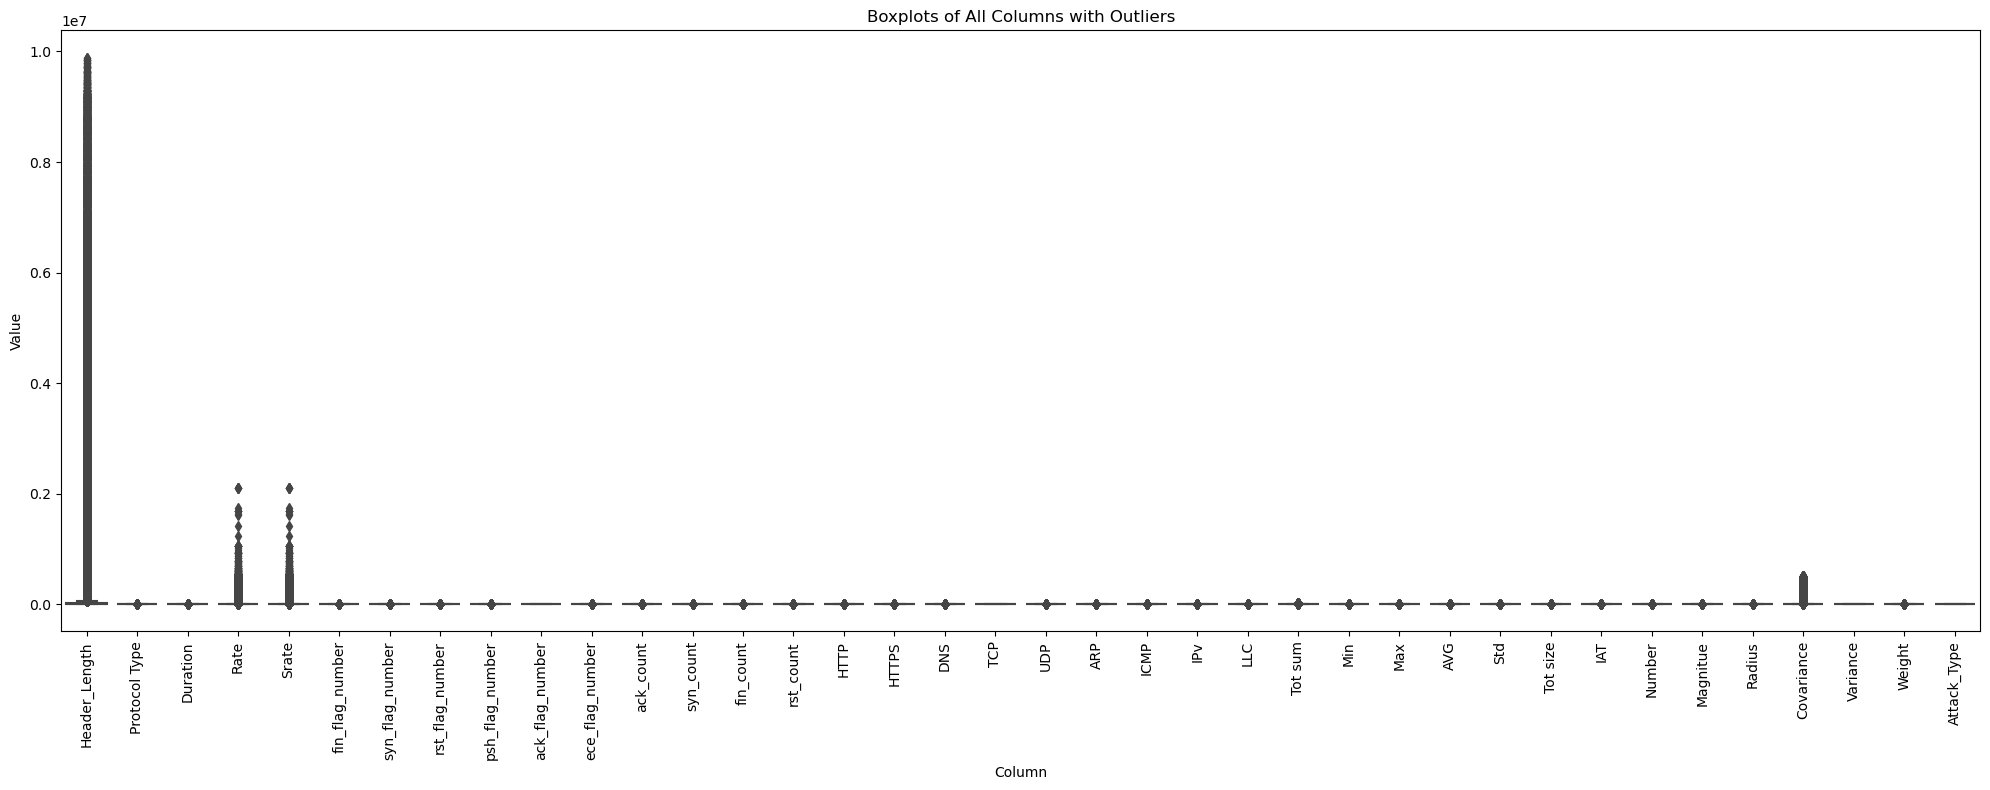

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert wide df (55 columns) into long format
df_melted = df2.melt(var_name="Column", value_name="Value")

plt.figure(figsize=(20, 8))  # wider figure to fit all columns on x-axis
sns.boxplot(x="Column", y="Value", data=df_melted)

plt.xticks(rotation=90)  # rotate labels for readability
plt.title("Boxplots of All Columns with Outliers")
plt.tight_layout()
plt.show()

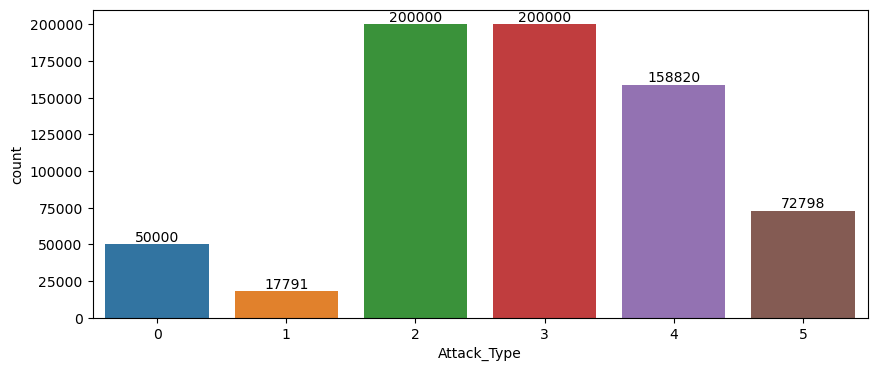

In [25]:
plt.figure(figsize=(10,4))
ax = sns.countplot(x='Attack_Type',data=df2)
for i in ax.containers:
    ax.bar_label(i,)

In [26]:
df2.shape

(699409, 38)

In [27]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Split features/labels
X = df2.drop(columns=['Attack_Type'])
y = df2['Attack_Type']

# Train-test split first (important to avoid leakage!)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Apply SMOTE on training set only
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print(y_train.value_counts())
print(y_train_bal.value_counts())

Attack_Type
3    160000
2    160000
4    127056
5     58238
0     40000
1     14233
Name: count, dtype: int64
Attack_Type
5    160000
4    160000
3    160000
2    160000
1    160000
0    160000
Name: count, dtype: int64


<h2>ML Models</h2>


🔹 Training Logistic Regression...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Logistic Regression Performance:
  Accuracy:  0.9663
  Precision: 0.9674
  Recall:    0.9663
  F1-score:  0.9666

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.90      0.86     10000
           1       0.63      0.63      0.63      3558
           2       1.00      1.00      1.00     40000
           3       0.99      1.00      1.00     40000
           4       0.98      0.98      0.98     31764
           5       0.97      0.90      0.93     14560

    accuracy                           0.97    139882
   macro avg       0.90      0.90      0.90    139882
weighted avg       0.97      0.97      0.97    139882



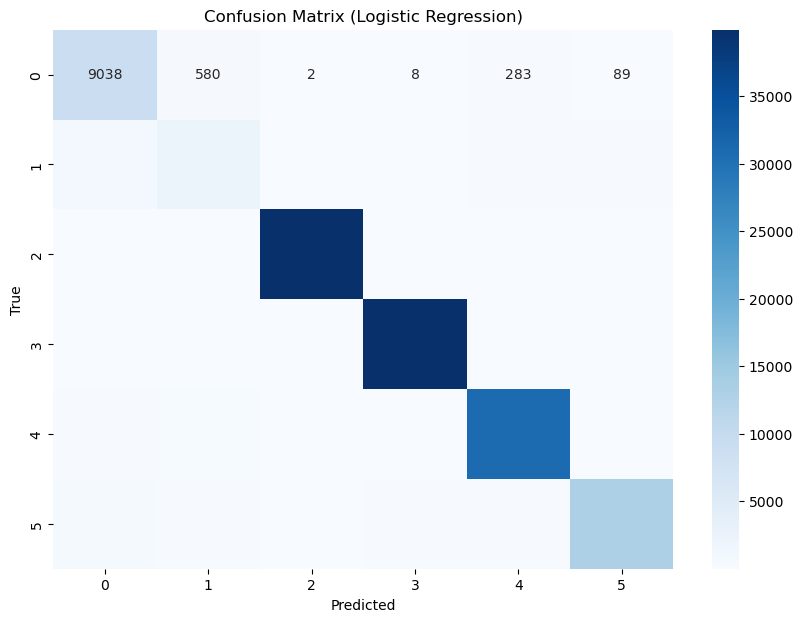


🔹 Training Random Forest...
Random Forest Performance:
  Accuracy:  0.9875
  Precision: 0.9877
  Recall:    0.9875
  F1-score:  0.9876

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.96      0.95     10000
           1       0.85      0.86      0.85      3558
           2       1.00      1.00      1.00     40000
           3       1.00      1.00      1.00     40000
           4       1.00      0.99      0.99     31764
           5       0.98      0.96      0.97     14560

    accuracy                           0.99    139882
   macro avg       0.96      0.96      0.96    139882
weighted avg       0.99      0.99      0.99    139882



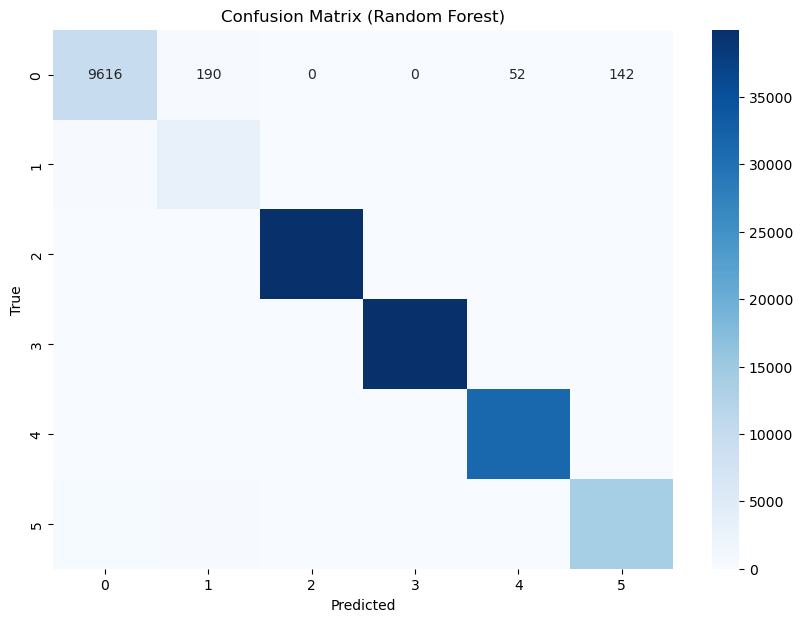


🔹 Training XGBoost...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [22:07:57] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Performance:
  Accuracy:  0.9871
  Precision: 0.9873
  Recall:    0.9871
  F1-score:  0.9872

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.97      0.94     10000
           1       0.85      0.84      0.85      3558
           2       1.00      1.00      1.00     40000
           3       1.00      1.00      1.00     40000
           4       0.99      0.99      0.99     31764
           5       0.99      0.96      0.97     14560

    accuracy                           0.99    139882
   macro avg       0.96      0.96      0.96    139882
weighted avg       0.99      0.99      0.99    139882



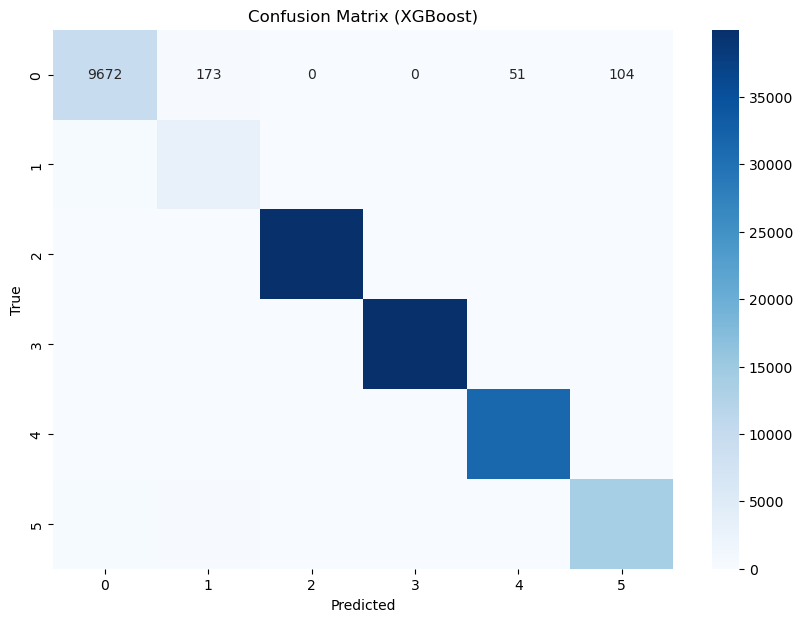


🔹 Training KNN...
KNN Performance:
  Accuracy:  0.9756
  Precision: 0.9764
  Recall:    0.9756
  F1-score:  0.9759

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.92      0.90     10000
           1       0.69      0.73      0.71      3558
           2       1.00      1.00      1.00     40000
           3       1.00      1.00      1.00     40000
           4       0.99      0.98      0.99     31764
           5       0.97      0.93      0.95     14560

    accuracy                           0.98    139882
   macro avg       0.92      0.93      0.92    139882
weighted avg       0.98      0.98      0.98    139882



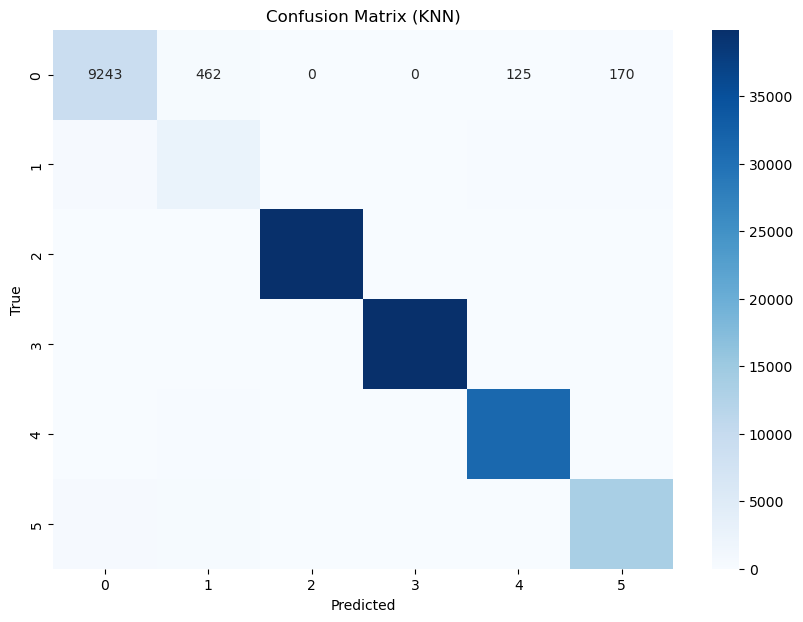


🔹 Training Naive Bayes...
Naive Bayes Performance:
  Accuracy:  0.8978
  Precision: 0.9115
  Recall:    0.8978
  F1-score:  0.8998

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.82      0.83     10000
           1       0.47      0.75      0.58      3558
           2       0.84      0.98      0.91     40000
           3       0.97      0.80      0.88     40000
           4       0.98      0.95      0.97     31764
           5       0.94      0.90      0.92     14560

    accuracy                           0.90    139882
   macro avg       0.84      0.87      0.85    139882
weighted avg       0.91      0.90      0.90    139882



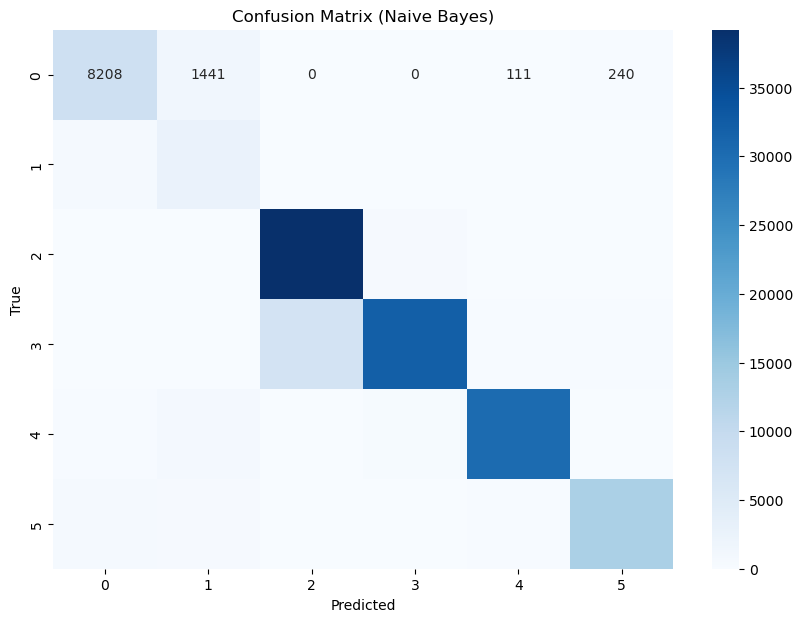


🔹 Training Decision Tree...
Decision Tree Performance:
  Accuracy:  0.9775
  Precision: 0.9779
  Recall:    0.9775
  F1-score:  0.9775

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.95      0.90     10000
           1       0.75      0.71      0.73      3558
           2       1.00      1.00      1.00     40000
           3       1.00      1.00      1.00     40000
           4       0.98      0.99      0.98     31764
           5       0.98      0.93      0.95     14560

    accuracy                           0.98    139882
   macro avg       0.93      0.93      0.93    139882
weighted avg       0.98      0.98      0.98    139882



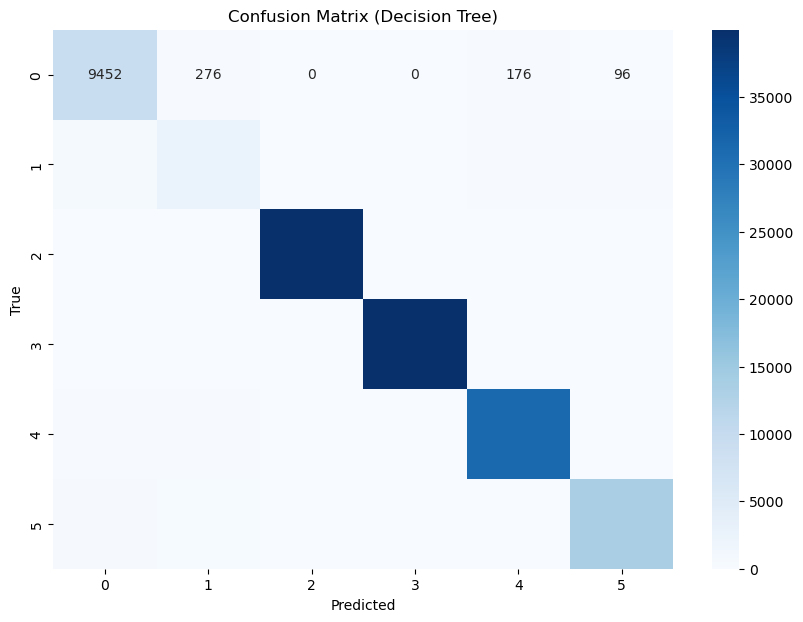


🔹 Training AdaBoost...
AdaBoost Performance:
  Accuracy:  0.8541
  Precision: 0.8442
  Recall:    0.8541
  F1-score:  0.8283

Classification Report:
               precision    recall  f1-score   support

           0       0.67      0.37      0.48     10000
           1       0.09      0.00      0.01      3558
           2       0.86      0.98      0.91     40000
           3       0.98      0.98      0.98     40000
           4       0.74      0.99      0.85     31764
           5       0.96      0.40      0.57     14560

    accuracy                           0.85    139882
   macro avg       0.72      0.62      0.63    139882
weighted avg       0.84      0.85      0.83    139882



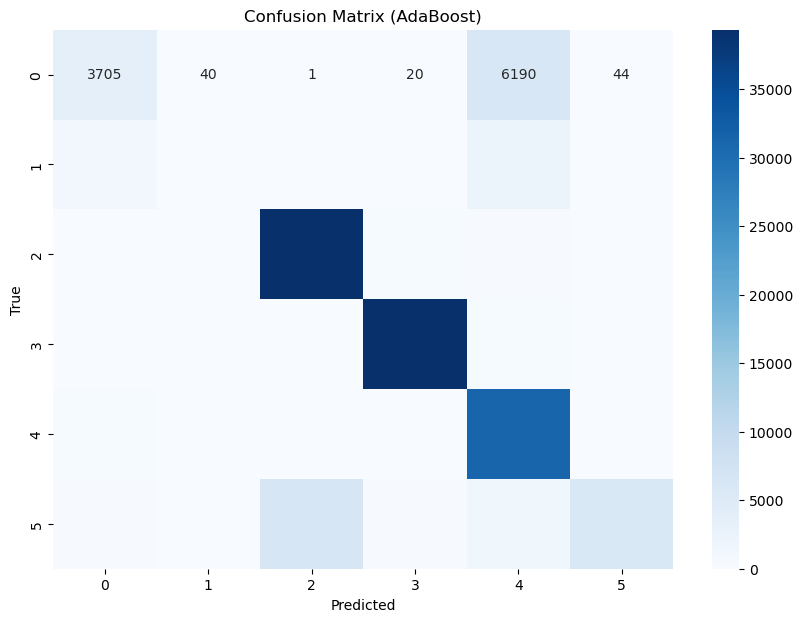


🔹 Training Extra Trees...
Extra Trees Performance:
  Accuracy:  0.9860
  Precision: 0.9862
  Recall:    0.9860
  F1-score:  0.9861

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.96      0.94     10000
           1       0.83      0.84      0.84      3558
           2       1.00      1.00      1.00     40000
           3       1.00      1.00      1.00     40000
           4       1.00      0.99      0.99     31764
           5       0.98      0.96      0.97     14560

    accuracy                           0.99    139882
   macro avg       0.95      0.96      0.96    139882
weighted avg       0.99      0.99      0.99    139882



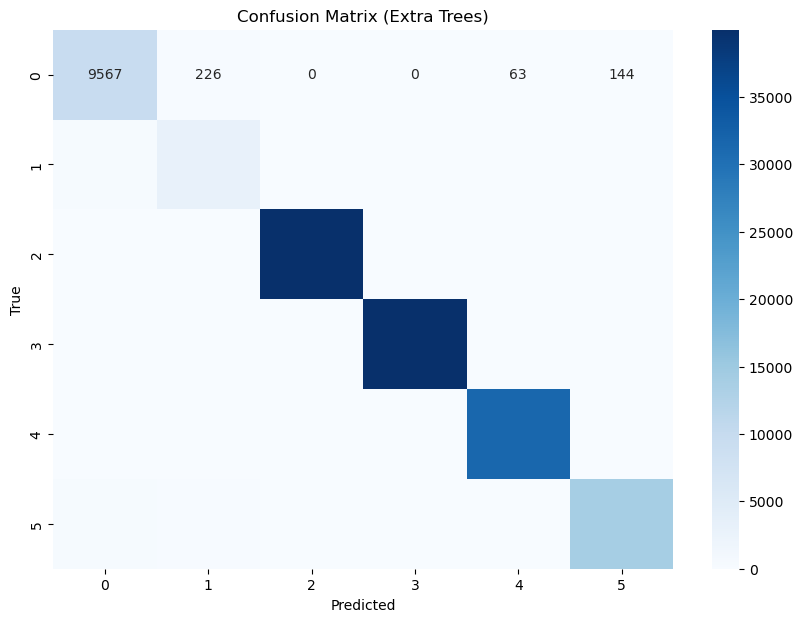


🔹 Training LightGBM...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM Performance:
  Accuracy:  0.9882
  Precision: 0.9883
  Recall:    0.9882
  F1-score:  0.9882

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.96      0.95     10000
           1       0.85      0.86      0.85      3558
           2       1.00      1.00      1.00     40000
           3       1.00      1.00      1.00     40000
           4       1.00      0.99      0.99     31764
           5       0.98      0.96      0.97     14560

    accuracy                           0.99    139882
   macro avg       0.96      0.96      0.96    139882
weighted avg       0.99      0.99      0.99    139882



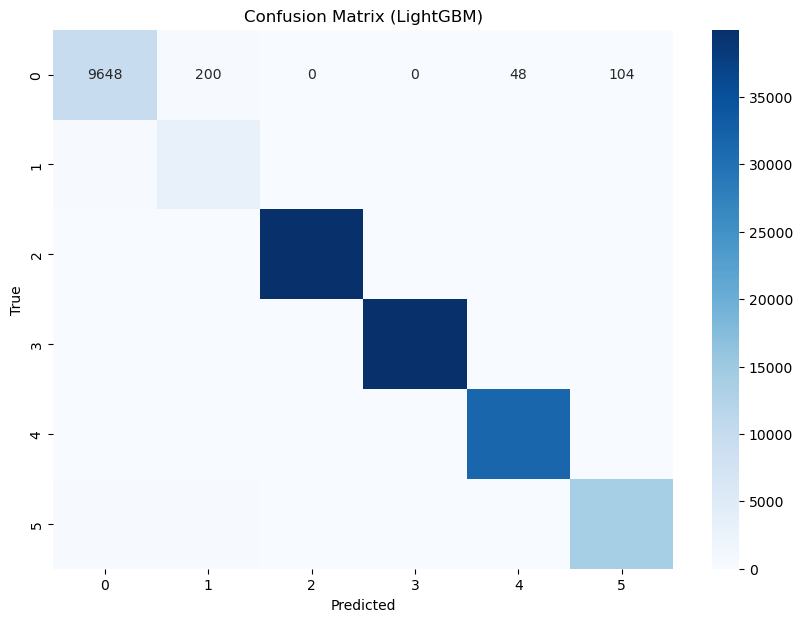


🔹 Training CatBoost...
CatBoost Performance:
  Accuracy:  0.9835
  Precision: 0.9840
  Recall:    0.9835
  F1-score:  0.9836

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.96      0.93     10000
           1       0.83      0.80      0.82      3558
           2       1.00      1.00      1.00     40000
           3       1.00      1.00      1.00     40000
           4       0.99      0.99      0.99     31764
           5       0.98      0.95      0.96     14560

    accuracy                           0.98    139882
   macro avg       0.95      0.95      0.95    139882
weighted avg       0.98      0.98      0.98    139882



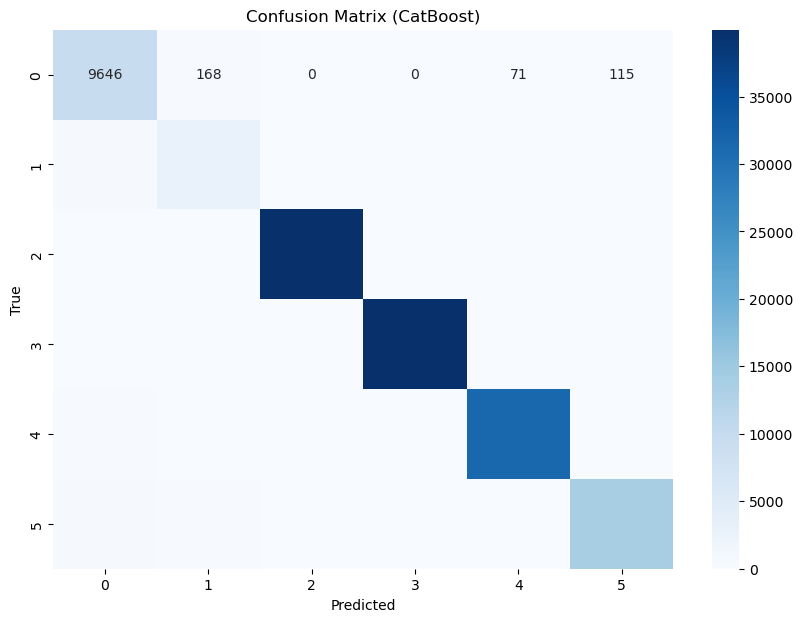


📊 Final Comparison:
                      Accuracy  Precision    Recall  F1-score
Logistic Regression  0.966329   0.967376  0.966329  0.966588
Random Forest        0.987525   0.987682  0.987525  0.987576
XGBoost              0.987146   0.987348  0.987146  0.987182
KNN                  0.975629   0.976413  0.975629  0.975925
Naive Bayes          0.897800   0.911509  0.897800  0.899833
Decision Tree        0.977467   0.977903  0.977467  0.977473
AdaBoost             0.854127   0.844227  0.854127  0.828275
Extra Trees          0.986038   0.986250  0.986038  0.986102
LightGBM             0.988197   0.988347  0.988197  0.988245
CatBoost             0.983536   0.983958  0.983536  0.983591


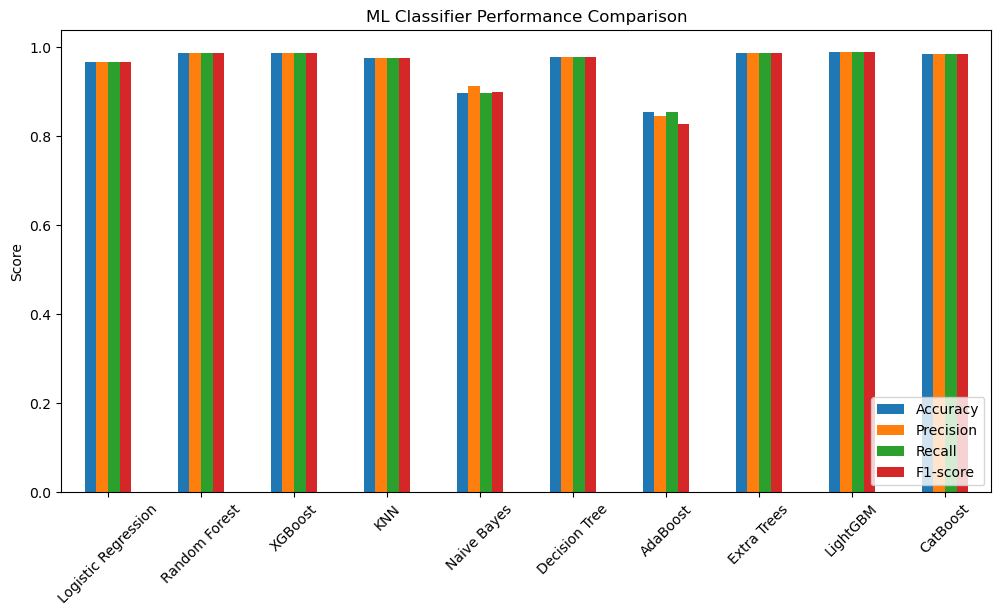

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


# Encode labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Feature scaling (important for SVM, KNN, LR)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# =====================================
# Define Models
# =====================================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, multi_class="multinomial", solver="lbfgs"),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, use_label_encoder=False, eval_metric="mlogloss", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=-1, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=42)
}

results = {}

# =====================================
# Train & Evaluate
# =====================================
for name, model in models.items():
    print(f"\n🔹 Training {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    results[name] = {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1}

    print(f"{name} Performance:")
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall:    {rec:.4f}")
    print(f"  F1-score:  {f1:.4f}")
    print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=encoder.classes_.astype(str)))

    # Confusion Matrix
    class_names = encoder.classes_

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(10,7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names,
                yticklabels=class_names)
    plt.title(f"Confusion Matrix ({name})")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.savefig(f"ML-Multi-Attack_type/Multiclass-ml-{name}.pdf")   # <-- save as PDF
    plt.show()


# =====================================
# Compare Results
# =====================================
results_df = pd.DataFrame(results).T
print("\n📊 Final Comparison:\n", results_df)

# Bar Plot Comparison
results_df.plot(kind="bar", figsize=(12,6))
plt.title("ML Classifier Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.savefig("ML-Multi-Attack_type/Multi-ml-compare.pdf")   # <-- save as PDF
plt.show()


<h3>with k5-fold cross validation</h3>


🔹 Training Logistic Regression with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\linear_model\

Logistic Regression Avg Performance:
  Accuracy:  0.9632
  Precision: 0.9631
  Recall:    0.9632
  F1-score:  0.9625

🔹 Training Random Forest with 5-Fold Cross Validation...
Random Forest Avg Performance:
  Accuracy:  0.9823
  Precision: 0.9819
  Recall:    0.9823
  F1-score:  0.9814

🔹 Training XGBoost with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [23:19:52] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [23:20:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [23:20:55] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [23:21:27] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:7

XGBoost Avg Performance:
  Accuracy:  0.9820
  Precision: 0.9816
  Recall:    0.9820
  F1-score:  0.9811

🔹 Training KNN with 5-Fold Cross Validation...
KNN Avg Performance:
  Accuracy:  0.9723
  Precision: 0.9720
  Recall:    0.9723
  F1-score:  0.9718

🔹 Training Naive Bayes with 5-Fold Cross Validation...
Naive Bayes Avg Performance:
  Accuracy:  0.9149
  Precision: 0.9277
  Recall:    0.9149
  F1-score:  0.9169

🔹 Training Decision Tree with 5-Fold Cross Validation...
Decision Tree Avg Performance:
  Accuracy:  0.9741
  Precision: 0.9744
  Recall:    0.9741
  F1-score:  0.9735

🔹 Training AdaBoost with 5-Fold Cross Validation...
AdaBoost Avg Performance:
  Accuracy:  0.8588
  Precision: 0.8462
  Recall:    0.8588
  F1-score:  0.8342

🔹 Training Extra Trees with 5-Fold Cross Validation...
Extra Trees Avg Performance:
  Accuracy:  0.9816
  Precision: 0.9812
  Recall:    0.9816
  F1-score:  0.9809

🔹 Training LightGBM with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMCla

LightGBM Avg Performance:
  Accuracy:  0.9828
  Precision: 0.9824
  Recall:    0.9828
  F1-score:  0.9819

🔹 Training CatBoost with 5-Fold Cross Validation...
CatBoost Avg Performance:
  Accuracy:  0.9791
  Precision: 0.9790
  Recall:    0.9791
  F1-score:  0.9783

📊 Final Comparison (5-Fold CV):
                      Accuracy  Precision    Recall  F1-score
Logistic Regression  0.963159   0.963056  0.963159  0.962509
Random Forest        0.982328   0.981886  0.982328  0.981395
XGBoost              0.982012   0.981623  0.982012  0.981117
KNN                  0.972268   0.971994  0.972268  0.971825
Naive Bayes          0.914940   0.927673  0.914940  0.916879
Decision Tree        0.974051   0.974445  0.974051  0.973470
AdaBoost             0.858776   0.846154  0.858776  0.834180
Extra Trees          0.981589   0.981211  0.981589  0.980877
LightGBM             0.982818   0.982367  0.982818  0.981907
CatBoost             0.979101   0.978958  0.979101  0.978250


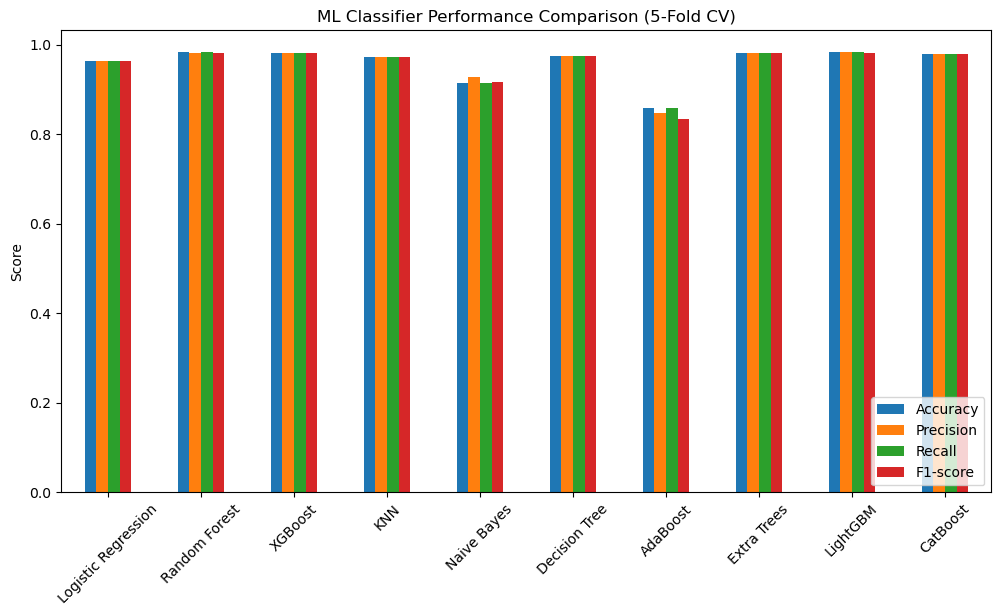

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# =============================
# Encode labels
# =============================
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# =============================
# Define Models
# =============================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, multi_class="multinomial", solver="lbfgs"),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, use_label_encoder=False, eval_metric="mlogloss", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=-1, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=42)
}

results = {}
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# =============================
# Train & Cross-Validate
# =============================
for name, model in models.items():
    print(f"\n🔹 Training {name} with 5-Fold Cross Validation...")

    acc_scores, prec_scores, rec_scores, f1_scores = [], [], [], []

    fold = 1
    for train_idx, test_idx in kf.split(X, y_encoded):
        # Use iloc to index rows correctly
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y_encoded[train_idx], y_encoded[test_idx]

        # Feature scaling
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

        # Train & predict
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)


        # Metrics
        acc_scores.append(accuracy_score(y_test, y_pred))
        prec_scores.append(precision_score(y_test, y_pred, average="weighted", zero_division=0))
        rec_scores.append(recall_score(y_test, y_pred, average="weighted", zero_division=0))
        f1_scores.append(f1_score(y_test, y_pred, average="weighted", zero_division=0))

        # Save one confusion matrix per fold (optional)
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(6,5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=encoder.classes_,
                    yticklabels=encoder.classes_)
        plt.title(f"{name} - Confusion Matrix (Fold {fold})")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.savefig(f"ML-Multi-Attack_type/Multi-ml-{name}-fold{fold}.pdf")
        plt.close()
        fold += 1

    # Average results
    results[name] = {
        "Accuracy": np.mean(acc_scores),
        "Precision": np.mean(prec_scores),
        "Recall": np.mean(rec_scores),
        "F1-score": np.mean(f1_scores)
    }

    print(f"{name} Avg Performance:")
    print(f"  Accuracy:  {np.mean(acc_scores):.4f}")
    print(f"  Precision: {np.mean(prec_scores):.4f}")
    print(f"  Recall:    {np.mean(rec_scores):.4f}")
    print(f"  F1-score:  {np.mean(f1_scores):.4f}")

# =============================
# Compare Results
# =============================
results_df = pd.DataFrame(results).T
print("\n📊 Final Comparison (5-Fold CV):\n", results_df)

# Bar Plot Comparison
results_df.plot(kind="bar", figsize=(12,6))
plt.title("ML Classifier Performance Comparison (5-Fold CV)")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.savefig("ML-Multi-Attack_type/Multi-ml-compare-5fold.pdf")
plt.show()
